In [21]:
import pandas as pd 
import numpy as np
import json
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

## Nightly price prediction price model 

#### Input features
1. price_per_night
2. parking
3. city
4. region
5. neighborhood
6. wifi
7. age
8. air_condition
9. fan
10. furnished
11. swimming_pool
12. currency
13. Refrigerator

In [2]:
df_original = pd.read_csv('../data_set/listings2.csv')
df = df_original.copy()

columns = ['bedrooms', 'beds', 'bathrooms', 'bathrooms_text', 'property_type', 'room_type', 'host_location', 'amenities', 'latitude', 'longitude', 'price']

df = df[columns]

#### 1. Data cleaning

1. All record with null price are been removed

In [3]:
df = df.dropna(subset='price')

df['price'] = (
    df['price']
        .str.replace('$', '', regex=False)
        .str.replace(',', '', regex=False)
)
# expected_columns = ['bedrooms', 'beds', 'bathrooms', 'property_type', 'room_type', 'price', 'wifi', 'air_condition']


In [4]:
# Since the null values in the bedrooms series are only 23 then replacing 
# them with the mean makes sense
df['bedrooms'] = (df['bedrooms'].fillna(value=df['bedrooms'].mean())).astype(int)

# beds: I replace all null beds with the minimum beds
df['beds'] = (df['beds'].fillna(value=df['beds'].min())).astype(int)

In [5]:
# Extracting values from bathrooms_text for the bathrooms column

df['bathrooms'] = pd.to_numeric(
    df['bathrooms_text']
        .str.extract(
            r'(\d+(?:\.\d+)?)'
        )[0],
    errors='coerce'
)

# beds: I replace all null bathrooms with the minimum bathrooms
df['bathrooms'] = df['bathrooms'].fillna(value=df['bathrooms'].min()).round(0).astype(int)
df = df.drop(columns='bathrooms_text')

In [6]:
# All records with null host_location has been drop
df = df.dropna(subset=['host_location'])

df['price']

0         97.00
4        424.29
5        225.00
8        187.91
10       273.00
          ...  
10605    235.00
10607    360.00
10608    295.00
10609    290.00
10611    225.00
Name: price, Length: 4900, dtype: str

### 2. Feature engineering

#### Room_type
previously having 
- Private room
- Entire home/apt


I modify it to:
- Private room -> normal room -> 1
- Entire home/apt -> single room self-contain -> 2

In [7]:
condition = [
    df['room_type'] == 'Private room',
    df['room_type'] == 'Entire home/apt'
]

choice = [1, 2]

df['room_type'] = np.select(condition, choice, default=1)

### Property_type feature(categorical)

- I used One-hot encoding to encode the property_type category

In [8]:
df['property_type'].value_counts()

condition = [
    (df['property_type'] == 'Entire rental unit') | (df['property_type'] == 'Entire condo') | (df['property_type'] == 'Entire serviced apartment') | (df['property_type'] == 'Private room in townhouse') | (df['property_type'] == 'Entire guest suite') | (df['property_type'] == 'Entire guesthouse') | (df['property_type'] == 'Private room in villa'),
    (df['property_type'] == 'Entire home') | (df['property_type'] == 'Houseboat') | (df['property_type'] == 'Entire place') | (df['property_type'] == 'Entire villa') | (df['property_type'] == 'Tiny home'),
    (df['property_type'] == 'Private room in rental unit') | (df['property_type'] == 'Private room in bed and breakfast') | (df['property_type'] == 'Private room in condo') | (df['property_type'] == 'Private room in home') | (df['property_type'] == 'Private room in guest suite') | (df['property_type'] == 'Private room in boat') | (df['property_type'] == 'Private room in loft') | (df['property_type'] == 'Private room in serviced apartment') | (df['property_type'] == 'Private room') | (df['property_type'] == 'Private room in nature lodge') | (df['property_type'] == 'Room in serviced apartment'),
    (df['property_type'] == 'Entire townhouse'),
    (df['property_type'] == 'Room in hotel') | (df['property_type'] == 'Room in boutique hotel') | (df['property_type'] == 'Room in aparthotel'),
    (df['property_type'] == 'Private room in guesthouse'),
]

choice = [
    'Apartment',
    'House',
    'Lodge',
    'Real estate',
    'Hotel',
    'Guest house'
]

df['property_type'] = np.select(condlist=condition, choicelist=choice, default='Hotel')

df = pd.get_dummies(
    df,
    columns=['property_type'],
    dtype=int
)

#### City feature

In [9]:
df['city'] = (
    df['host_location'].apply(lambda x: x.split(' ')[0])
    .str.replace(',', '', regex=False)
)

df = df.drop(columns='host_location')

# applying one-hot encoding to the city category
df = pd.get_dummies(
    df,
    columns=['city'],
    dtype=int
)

In [10]:
# Extracting parking, refrigerator, air-condition, and wifi

def parse_amenities(amenities):
    if amenities is None:
        return []

    try:
        parsed = json.loads(amenities)
        return parsed if isinstance(parsed, list) else []
    except (json.JSONDecoderError, TypeError):
        return []

df['amenities'] = df['amenities'].apply(parse_amenities)

In [11]:
df['refrigerator'] = df['amenities'].apply(lambda x: int('refrigerator' in [b.lower() for b in x]))
df['wifi'] = df['amenities'].apply(lambda x: int('wifi' in [b.lower() for b in x]))
df['parking'] = df['amenities'].apply(lambda x: int('parking' in [b.lower() for b in x]))
df['currency'] = 'usd'

In [12]:
df = (df.drop(columns='amenities')).drop_duplicates()

In [13]:
price = df['price'].astype(float)
df = df.drop(columns='price')
df.insert(loc=len(df.columns) - 1, column='price', value=price, allow_duplicates=False)

In [14]:
df.sort_values(by='price')

,bedrooms,beds,bathrooms,room_type,latitude,longitude,property_type_Apartment,property_type_Guest house,property_type_Hotel,property_type_House,...,city_Wicklow,city_Wijk,city_Willemstad,city_Zeist,city_Zunderdorp,refrigerator,wifi,parking,price,currency
6516,1,1,2,1,52.330942,4.876598,0,0,0,0,...,0,0,0,0,0,0,1,0,39.90,usd
3761,1,1,0,1,52.388100,4.914380,0,0,1,0,...,0,0,0,0,0,0,1,0,42.00,usd
5692,1,2,0,1,52.299496,4.996433,1,0,0,0,...,0,0,0,0,0,0,0,0,45.00,usd
2657,1,1,1,1,52.347400,4.789880,1,0,0,0,...,0,0,0,0,0,0,1,0,48.54,usd
6072,1,1,1,1,52.368080,4.854300,0,0,0,0,...,0,0,0,0,0,0,1,0,57.34,usd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6116,4,4,4,2,52.368986,4.887528,0,0,0,1,...,0,0,0,0,0,1,1,0,4439.60,usd
3402,1,2,1,2,52.353490,4.866770,1,0,0,0,...,0,0,0,0,0,0,1,0,5706.00,usd
4365,17,30,17,2,52.402040,4.891470,0,0,1,0,...,0,0,0,0,0,0,0,0,7200.00,usd
4681,7,22,2,2,52.402010,4.890170,0,0,1,0,...,0,0,0,0,0,1,1,0,7200.00,usd


In [15]:
# df[df['price'] == 11581.20].T
df = df.reset_index()

df = df.drop(columns='index')

df = df.drop(index=140)

# export the cleaned data set
df.to_csv("../data_set/nightly_cleaned_data.csv")

#### 3. Investigate data or analyze data

In [16]:
df_investigate = df.sort_values(by='price', ascending=False)

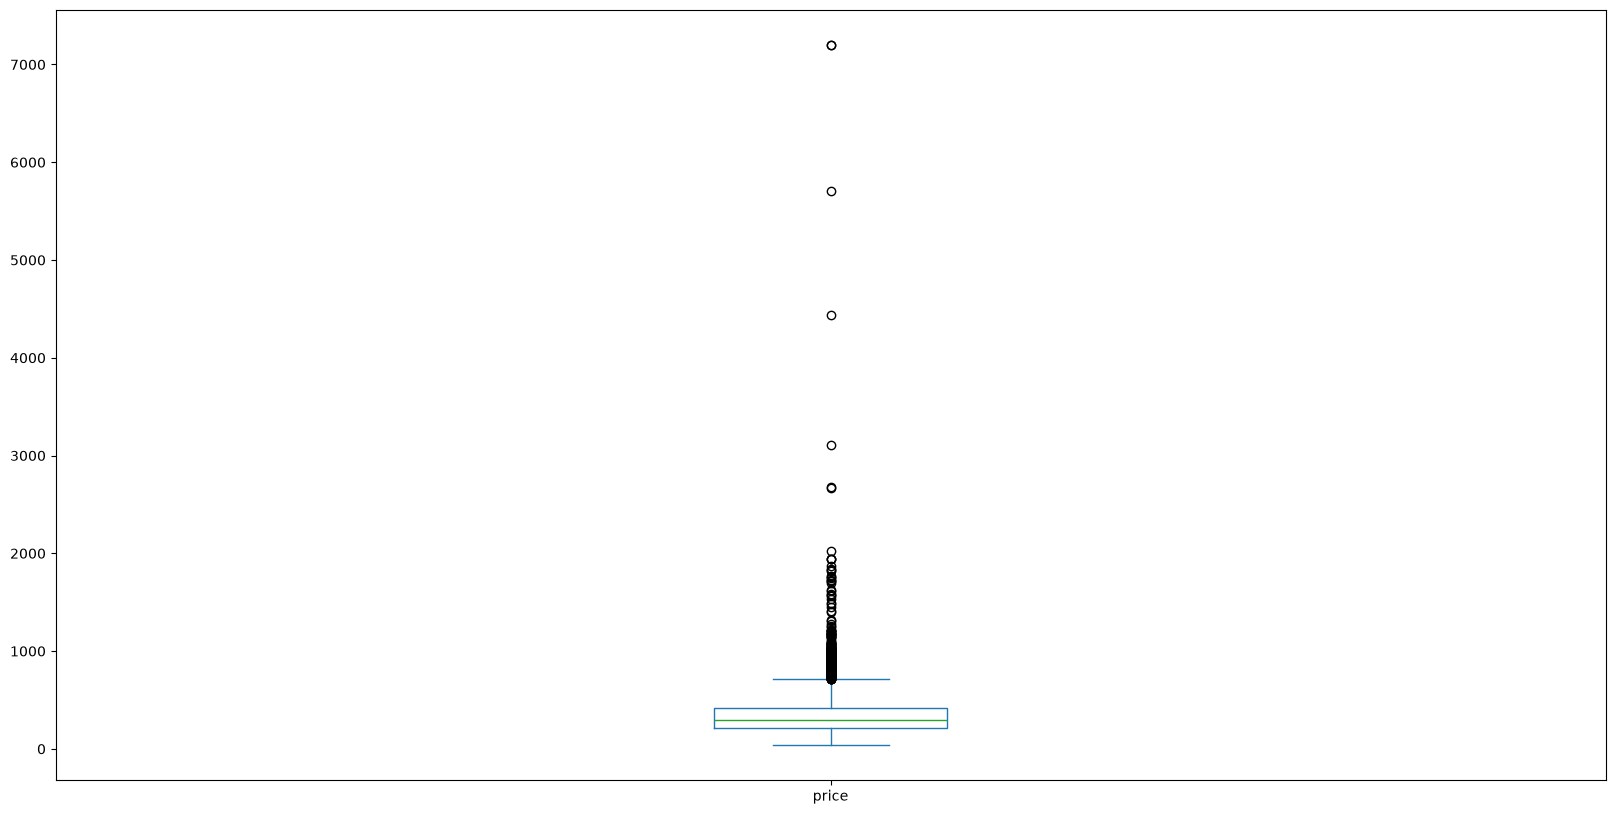

In [31]:
df_investigate.iloc[0, :]

df_investigate.plot(
    kind='box', 
    y='price',
    figsize=(20, 10)
)

fg = px.box(
    df_investigate,
    y=['price'],
    width=1000,
    height=500
)

In [32]:
fg.update_layout(
    yaxis_title='price',
    xaxis_title='features',
    title='Accommodation price distribution'
)

fg.show()

#### Decision on outliers

- I have investigate the outliers(expensive properties) and came to a conclusion that
    - Those records are correct observation because of some of the input features it's having, like;
        - bedrooms
        - bathrooms
        - refrigerator
        - property_type


Therefore I wouldn't remove them from the dataset. Even though it make the different between the median and mean very huge.

In [24]:
df_test = px.box(
    data_frame=df,
    x=df['price'],
    title='Accommodation price distribution'
)

df_test.show()

#### Visualizing the data using histogram
- The data appears to be right-skewed
    - mean > median > mode
- Most of the data in terms of 'price' is on the left side

In [39]:
fg_hist = px.histogram(
    data_frame=df,
    x='price',
    nbins=60,
    title='Accommodation price distribution',
    # marginal='rug',
    color_discrete_sequence=['#3366CC']
)

fg_hist.update_layout(
    xaxis_title='Price feature($)',
    yaxis_title='Frequency',
    width=1200,
    height=600
)

fg_hist.show()

In [44]:
print("mode: ", df['price'].mode())
print("mean: ", df['price'].mean())
print("median: ", df['price'].median())

mode:  0    237.0
Name: price, dtype: float64
mean:  349.9473809037007
median:  292.67


#### Log-scale visualization

In [52]:
df_temp = df.copy()
df_temp['log_price'] = np.log1p(df_temp['price'])

fg_hist_g = px.histogram(
    data_frame=df_temp,
    x='log_price',
    nbins=60,
    title='Accommodation price distribution',
    color_discrete_sequence=['#3366CC']
)

fg_hist_g.update_layout(
    width=1200,
    height=600,
    xaxis_title='Log price',
    yaxis_title='Frequency'
)

fg_hist_g.show()

#### Detecting outliers using IQR
- Formulaes 
    - Q1 = 25th percentile
    - Q3 = 75th percentile
- IQR = Q3 - Q1
    - low = Q1 - 1.5(IQR)
    - upper = Q3 + 1.5(IQR)

- So, prices above 'upper' is potential outliers

In [86]:
q1 = df['price'].quantile(q=0.25)
q3 = df['price'].quantile(q=0.75)

iqr = round((q3 - q1), 2)

lower_boundary = round(q1 - 1.5*iqr, 2)
upper_boundary = round(q3 + 1.5*iqr, 2)


print(f'Lower boundary: {lower_boundary}')
print(f'upper boundary: {upper_boundary}')

Lower boundary: -86.01
upper boundary: 713.74


In [ ]:
# So, these are unusual pricing
df[df['price'] > upper_boundary]

,bedrooms,beds,bathrooms,room_type,latitude,longitude,property_type_Apartment,property_type_Guest house,property_type_Hotel,property_type_House,...,city_Wicklow,city_Wijk,city_Willemstad,city_Zeist,city_Zunderdorp,refrigerator,wifi,parking,price,currency
16,3,4,1,2,52.364120,4.887570,0,0,0,1,...,0,0,0,0,0,1,1,0,958.33,usd
47,3,6,3,2,52.358610,4.860230,1,0,0,0,...,0,0,0,0,0,0,1,0,890.00,usd
53,4,5,2,2,52.354626,4.874215,1,0,0,0,...,0,0,0,0,0,1,1,0,1175.00,usd
68,3,3,2,2,52.376540,4.870030,0,0,1,0,...,0,0,0,0,0,1,0,0,795.00,usd
76,10,26,2,2,52.393300,4.885560,0,0,1,0,...,0,0,0,0,0,1,1,0,986.00,usd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4747,2,2,1,2,52.362940,4.899570,1,0,0,0,...,0,0,0,0,0,0,1,0,810.50,usd
4768,2,2,2,2,52.376321,4.880895,0,0,0,1,...,0,0,0,0,0,0,1,0,1000.00,usd
4778,3,3,2,2,52.375628,4.880452,0,0,0,1,...,0,0,0,0,0,0,1,0,990.00,usd
4786,4,4,2,2,52.357239,4.901226,0,0,0,1,...,0,0,0,0,0,1,1,0,1068.00,usd


In [67]:
df.shape

(4891, 145)